# Лабораторная работа 2. Рекомендательные системы

## 1. Датасет и задача

Используем **EB-NeRD Small** целиком: это уменьшенная версия датасета датского издания Ekstra Bladet для **RecSys Challenge 2024**

Датасет содержит пользователей, статьи, историю кликов и время событий: можно обучить рекомендации по неявному фидбеку и оценить их на следующем временном периоде

### Что рекомендуем?

Для пользователя ранжируем статьи из списка показа `article_ids_inview` и выбираем **Top-5**. Объект рекомендации - статья, целевое действие - клик. Релевантность равна 1, если статья входит в `article_ids_clicked`, иначе 0. Отсутствие клика не означает отрицательную оценку: пользователь мог не обратить внимания на статью


In [1]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from implicit.cpu.als import AlternatingLeastSquares
from scipy.sparse import csr_matrix
from threadpoolctl import threadpool_limits


### Загрузка

Скачиваем архив и распаковываем исходные таблицы


In [2]:
raw_dir = Path("/Users/eabochagova/study/ml/lab-1/lab-2/data/raw")
raw_dir.mkdir(parents=True, exist_ok=True)
archive_path = raw_dir / "ebnerd_small.zip"

urlretrieve("https://ebnerd-dataset.s3.eu-west-1.amazonaws.com/ebnerd_small.zip", archive_path)
with ZipFile(archive_path) as archive:
    archive.extractall(raw_dir)


### Таблицы и основные поля

| Таблица | Содержание |
|---|---|
| `articles` | Каталог статей с текстами, категориями и другими признаками |
| `train_behaviors` | Показы и клики обучающей недели |
| `train_history` | Предыстория пользователей до обучающей недели |
| `validation_behaviors` | Показы и клики следующей недели |
| `validation_history` | Предыстория пользователей до следующей недели |

Поля по описанию авторов:

| Поле | Значение |
|---|---|
| `user_id`, `impression_id`, `impression_time` | Пользователь, показ и его время |
| `article_ids_inview`, `article_ids_clicked` | Списки показанных и кликнутых статей |
| `article_id` в behaviors | Статья текущей страницы, пропуск означает главную страницу |
| `article_id_fixed`, `impression_time_fixed` в history | Согласованные списки прочитанных статей и времен чтения |
| `article_id`, `category_str` в articles | Ключ статьи и ее категория |


In [3]:
articles = pd.read_parquet(raw_dir / "articles.parquet")
train_behaviors = pd.read_parquet(raw_dir / "train" / "behaviors.parquet")
train_history = pd.read_parquet(raw_dir / "train" / "history.parquet")
validation_behaviors = pd.read_parquet(raw_dir / "validation" / "behaviors.parquet")
validation_history = pd.read_parquet(raw_dir / "validation" / "history.parquet")

## 2. Разведочный анализ данных

Различаем **показ** (подборку статей), **клик** (выбор статьи в показе) и **уникальную пару пользователь-статья** (взаимодействие независимо от числа повторных чтений)


In [4]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11})


### Таблица кликов

Разворачиваем `article_ids_clicked` через `explode`. Удаляем повторы `(impression_id, user_id, article_id)` внутри показа, повторные чтения в разных показах сохраняем


In [5]:
train_clicks = (
    train_behaviors[["impression_id", "user_id", "impression_time", "article_ids_clicked"]]
    .explode("article_ids_clicked")
    .rename(columns={"article_ids_clicked": "article_id"})
)
clicks_before = len(train_clicks)
repeated_in_impression = train_clicks.duplicated(["impression_id", "user_id", "article_id"]).sum()

train_clicks = train_clicks.drop_duplicates(["impression_id", "user_id", "article_id"]).reset_index(drop=True)
repeated_pairs = train_clicks.duplicated(["user_id", "article_id"]).sum()

print(f"Клики до обработки: {clicks_before:,}")
print(f"Повторы внутри одного показа: {repeated_in_impression:,}")
print(f"Клики после обработки: {len(train_clicks):,}")
print(f"Повторы пары пользователь - статья в разных показах: {repeated_pairs:,}")
display(train_clicks.head(3))

Клики до обработки: 234,277
Повторы внутри одного показа: 514
Клики после обработки: 233,763
Повторы пары пользователь - статья в разных показах: 3,903


,impression_id,user_id,impression_time,article_id
0,149474,139836,2023-05-24 07:47:53,9778657
1,150528,143471,2023-05-24 07:33:25,9778623
2,153068,151570,2023-05-24 07:09:04,9778669


### Объем, периоды и холодный старт

Уникальные статьи считаем по кликам и истории. Холодный старт определяем относительно `train_history` и кликов train: доли новых пользователей и статей считаем среди уникальных пользователей и уникальных кликнутых статей validation


In [6]:
train_users = set(train_clicks["user_id"])
train_article_ids = set(train_clicks["article_id"])
validation_users = set(validation_behaviors["user_id"])
validation_article_ids = set(validation_behaviors["article_ids_clicked"].explode())
history_article_ids = set(train_history["article_id_fixed"].explode())
validation_history_article_ids = set(validation_history["article_id_fixed"].explode())

sizes = pd.DataFrame([
    ["articles", len(articles), articles.shape[1], None, articles["article_id"].nunique()],
    ["train_behaviors", len(train_behaviors), train_behaviors.shape[1], len(train_users), len(train_article_ids)],
    ["train_history", len(train_history), train_history.shape[1], train_history["user_id"].nunique(), len(history_article_ids)],
    ["validation_behaviors", len(validation_behaviors), validation_behaviors.shape[1], len(validation_users), len(validation_article_ids)],
    ["validation_history", len(validation_history), validation_history.shape[1], validation_history["user_id"].nunique(), len(validation_history_article_ids)],
], columns=["Таблица", "Строк", "Столбцов", "Уникальных пользователей", "Уникальных статей"])
display(sizes.set_index("Таблица"))

periods = pd.DataFrame([
    ["train_history", train_history["impression_time_fixed"].map(min).min(), train_history["impression_time_fixed"].map(max).max()],
    ["train_behaviors", train_behaviors["impression_time"].min(), train_behaviors["impression_time"].max()],
    ["validation_history", validation_history["impression_time_fixed"].map(min).min(), validation_history["impression_time_fixed"].map(max).max()],
    ["validation_behaviors", validation_behaviors["impression_time"].min(), validation_behaviors["impression_time"].max()],
], columns=["Часть данных", "Начало", "Конец"])
display(periods.set_index("Часть данных"))

known_users = train_users | set(train_history["user_id"])
known_articles = train_article_ids | history_article_ids
new_users = len(validation_users - known_users)
new_articles = len(validation_article_ids - known_articles)

cold_start = pd.DataFrame({
    "Новых пользователей": [new_users],
    "Новых пользователей, %": [100 * new_users / len(validation_users)],
    "Новых статей": [new_articles],
    "Новых статей, %": [100 * new_articles / len(validation_article_ids)],
}, index=["Train + train_history"])
display(cold_start.round(2))

,Строк,Столбцов,Уникальных пользователей,Уникальных статей
Таблица,,,,
articles,20738,21,NaN,20738
train_behaviors,232887,17,15143.0,1892
train_history,15143,5,15143.0,8786
validation_behaviors,244647,17,15342.0,2062
validation_history,15342,5,15342.0,8709


,Начало,Конец
Часть данных,,
train_history,2023-04-27 07:00:00,2023-05-18 06:59:59
train_behaviors,2023-05-18 07:00:01,2023-05-25 06:59:58
validation_history,2023-05-04 07:00:00,2023-05-25 06:59:59
validation_behaviors,2023-05-25 07:00:02,2023-06-01 06:59:59


,Новых пользователей,"Новых пользователей, %",Новых статей,"Новых статей, %"
Train + train_history,3684,24.01,887,43.02


**Интерпретация.** Предыстория train заканчивается до его показов. В validation неизвестны обучению **24,01% пользователей** и **43,02% уникальных кликнутых статей**. Здесь «новые» означает отсутствие в обучающих взаимодействиях, а не первое посещение или публикацию на сайте

### Активность и разреженность

Описываем распределения кликов, длины предыстории и `read_time` - времени на текущей странице показа в секундах, которое не обязательно относится к кликнутой статье

Плотность матрицы кликов **только за период train**:

$$\text{density} = \frac{\#\text{уникальных пар пользователь-статья}}{\#\text{активных пользователей}\times\#\text{активных статей}},\qquad \text{sparsity} = 1 - \text{density}$$


In [7]:
user_clicks = train_clicks.groupby("user_id").size()
article_clicks = train_clicks.groupby("article_id").size()
history_lengths = train_history["article_id_fixed"].map(len)

distributions = {
    "Клики на пользователя": user_clicks,
    "Клики на статью": article_clicks,
    "Длина train_history": history_lengths,
    "read_time, секунды": train_behaviors["read_time"],
}
statistics = pd.DataFrame({name: values.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]) for name, values in distributions.items()}).T
statistics = statistics.rename(columns={"count": "Количество", "mean": "Среднее", "std": "Станд. отклонение", "min": "Минимум", "max": "Максимум"})
display(statistics.round(2))

unique_pairs = len(train_clicks.drop_duplicates(["user_id", "article_id"]))
density = unique_pairs / (len(train_users) * len(train_article_ids))
popularity = article_clicks.sort_values(ascending=False)
top_count = int(np.ceil(0.1 * len(popularity)))
top_click_share = 100 * popularity.iloc[:top_count].sum() / len(train_clicks)

print(f"Уникальные пары пользователь - статья: {unique_pairs:,}")
print(f"Плотность матрицы train: {density:.4%}")
print(f"Разреженность матрицы train: {1 - density:.4%}")
print(f"Верхние 10% статей ({top_count}) получают {top_click_share:.2f}% кликов train.")

,Количество,Среднее,Станд. отклонение,Минимум,25%,50%,75%,90%,99%,Максимум
Клики на пользователя,15143.0,15.44,17.80,1.0,3.0,9.0,21.0,38.0,83.00,155.0
Клики на статью,1892.0,123.55,177.33,1.0,2.0,8.0,223.0,377.8,737.08,1337.0
Длина train_history,15143.0,160.22,178.79,5.0,35.0,93.0,222.0,414.0,802.58,1896.0
"read_time, секунды",232887.0,43.90,90.30,0.0,11.0,21.0,45.0,92.0,366.00,1799.0


Уникальные пары пользователь - статья: 229,860
Плотность матрицы train: 0.8023%
Разреженность матрицы train: 99.1977%
Верхние 10% статей (190) получают 42.75% кликов train.


**Интерпретация.** Разреженность за период train - **99,20%**. Предыстория длиннее недельной истории кликов и дает дополнительные взаимодействия для персонализации

### Качество данных: пропуски

Показываем столбцы с внешними пропусками и отдельно проверяем пропуски внутри списков времени чтения и прокрутки истории


In [8]:
tables = {
    "articles": articles,
    "train_behaviors": train_behaviors,
    "train_history": train_history,
    "validation_behaviors": validation_behaviors,
    "validation_history": validation_history,
}

missing_tables = []
for name, table in tables.items():
    missing = pd.DataFrame({
        "Таблица": name,
        "Пропусков": table.isna().sum(),
        "Пропусков, %": 100 * table.isna().mean(),
    })
    missing_tables.append(missing[missing["Пропусков"] > 0])

missing = pd.concat(missing_tables).rename_axis("Поле").reset_index()
display(missing.round(2))

nested_missing_rows = []
for name, history in [("train_history", train_history), ("validation_history", validation_history)]:
    for column in ["read_time_fixed", "scroll_percentage_fixed"]:
        values = history[column].explode()
        nested_missing_rows.append([name, column, len(values), values.isna().sum(), 100 * values.isna().mean()])

nested_missing = pd.DataFrame(nested_missing_rows, columns=["Таблица", "Поле", "Элементов списка", "Пропусков внутри", "Пропусков внутри, %"])
display(nested_missing.round(2))


,Поле,Таблица,Пропусков,"Пропусков, %"
0,image_ids,articles,1878,9.06
1,total_inviews,articles,10770,51.93
2,total_pageviews,articles,10882,52.47
3,total_read_time,articles,10882,52.47
4,article_id,train_behaviors,162466,69.76
5,scroll_percentage,train_behaviors,163789,70.33
6,gender,train_behaviors,216668,93.04
7,postcode,train_behaviors,228214,97.99
8,age,train_behaviors,226546,97.28
9,next_read_time,train_behaviors,6218,2.67


,Таблица,Поле,Элементов списка,Пропусков внутри,"Пропусков внутри, %"
0,train_history,read_time_fixed,2426247,0,0.00
1,train_history,scroll_percentage_fixed,2426247,255076,10.51
2,validation_history,read_time_fixed,2204173,0,0.00
3,validation_history,scroll_percentage_fixed,2204173,213516,9.69


**Интерпретация.** В ключевых полях показов внешних пропусков нет. Около 69,8% контекстных `article_id` train пусты: это допустимые показы на главной странице. Демографию не заполняем - она не используется моделями

В `scroll_percentage_fixed` пропущены 10,51% элементов train и 9,69% validation, время чтения историй заполнено. Для бинарной матрицы кликов эти пропуски не требуют удаления строк

### Качество данных: дубли и связи

Проверяем уникальность ключей исходных таблиц. Для кликов train проверяем наличие статьи в каталоге и среди кандидатов соответствующего показа


In [9]:
duplicate_rows = []
for name, table, key in [
    ("articles", articles, "article_id"),
    ("train_behaviors", train_behaviors, "impression_id"),
    ("validation_behaviors", validation_behaviors, "impression_id"),
    ("train_history", train_history, "user_id"),
    ("validation_history", validation_history, "user_id"),
]:
    duplicate_rows.append([name, key, table.duplicated(key).sum()])

duplicates = pd.DataFrame(duplicate_rows, columns=["Таблица", "Ключ", "Повторных строк по ключу"])
display(duplicates)

outside_catalog = (~train_clicks["article_id"].isin(articles["article_id"])).sum()
outside_inview = sum(not set(clicked).issubset(set(shown)) for clicked, shown in zip(train_behaviors["article_ids_clicked"], train_behaviors["article_ids_inview"]))
print(f"Клики train по статьям вне каталога: {outside_catalog}")
print(f"Показы train с кликнутыми статьями вне списка показанных: {outside_inview}")

,Таблица,Ключ,Повторных строк по ключу
0,articles,article_id,0
1,train_behaviors,impression_id,0
2,validation_behaviors,impression_id,0
3,train_history,user_id,0
4,validation_history,user_id,0


Клики train по статьям вне каталога: 0
Показы train с кликнутыми статьями вне списка показанных: 0


**Интерпретация.** Дублей ключей нет. Все кликнутые статьи train найдены в каталоге и в списке кандидатов своего показа

### Качество данных: выбросы и допустимые значения

Потенциальные выбросы отмечаем по границе $Q_3 + 1{,}5\cdot IQR$, где $IQR=Q_3-Q_1$. Превышение границы само по себе не доказывает ошибку

Отдельно проверяем отрицательное время чтения и прокрутку вне диапазона 0-100. В сводке «проверено значений» - сумма непустых значений проверяемых полей, а не число строк


In [10]:
outlier_rows = []
for name, values in distributions.items():
    q1, q3 = values.quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    count = (values > upper).sum()
    outlier_rows.append([name, upper, count, 100 * count / values.count()])

outliers = pd.DataFrame(outlier_rows, columns=["Показатель", "Верхняя граница IQR", "Выше границы", "Выше границы, %"])
display(outliers.round(2))

invalid_rows = []
for name, behavior in [("train_behaviors", train_behaviors), ("validation_behaviors", validation_behaviors)]:
    for column in ["read_time", "next_read_time", "scroll_percentage", "next_scroll_percentage"]:
        values = behavior[column]
        invalid = values < 0 if "read_time" in column else (values < 0) | (values > 100)
        invalid_rows.append([name, column, values.count(), invalid.sum()])

for name, history in [("train_history", train_history), ("validation_history", validation_history)]:
    for column in ["read_time_fixed", "scroll_percentage_fixed"]:
        values = pd.to_numeric(history[column].explode())
        invalid = values < 0 if "read_time" in column else (values < 0) | (values > 100)
        invalid_rows.append([name, column, values.count(), invalid.sum()])

invalid_values = pd.DataFrame(invalid_rows, columns=["Таблица", "Поле", "Непропущенных значений", "Некорректных значений"])
invalid_summary = invalid_values.groupby("Таблица", sort=False)[
    ["Непропущенных значений", "Некорректных значений"]
].sum().rename(columns={"Непропущенных значений": "Проверено значений"})
display(invalid_summary)

,Показатель,Верхняя граница IQR,Выше границы,"Выше границы, %"
0,Клики на пользователя,48.0,933,6.16
1,Клики на статью,554.5,54,2.85
2,Длина train_history,502.5,943,6.23
3,"read_time, секунды",96.0,21500,9.23


,Проверено значений,Некорректных значений
Таблица,,
train_behaviors,735271,0
validation_behaviors,768001,0
train_history,4597418,0
validation_history,4194830,0


**Интерпретация.** IQR отмечает длинные хвосты активности, популярности и времени чтения, автоматически такие наблюдения не удаляем. В проверенных полях показов и историй недопустимых значений нет

### Визуализации

Графики строим по кликам train. Готовые `total_pageviews`, `total_inviews` и `total_read_time` не используем: их период агрегации может выходить за границы обучения

**Активность пользователей.** Логарифмические интервалы показывают редких и активных читателей


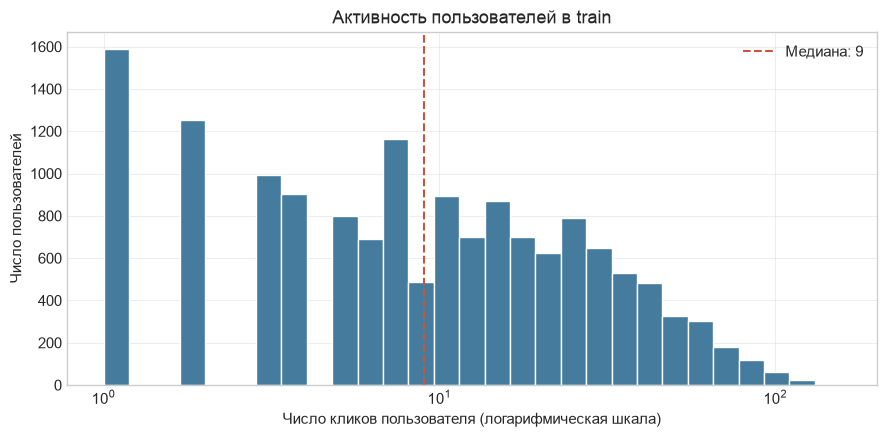

In [11]:
fig, ax = plt.subplots()
ax.hist(user_clicks, bins=np.geomspace(1, user_clicks.max() + 1, 30), color="#457b9d", edgecolor="white")
ax.set_xscale("log")
ax.axvline(user_clicks.median(), color="#c8553d", linestyle="--", label=f"Медиана: {user_clicks.median():.0f}")
ax.set(title="Активность пользователей в train", xlabel="Число кликов пользователя (логарифмическая шкала)", ylabel="Число пользователей")
ax.legend()
fig.tight_layout()
plt.show()

**Интерпретация.** Медиана - 9 кликов, среднее - 15,44, у четверти пользователей не более 3 кликов за train. Для персонализации таких пользователей особенно важна предыстория

**Популярность статей.** Ранжируем статьи по числу кликов, обе оси логарифмические


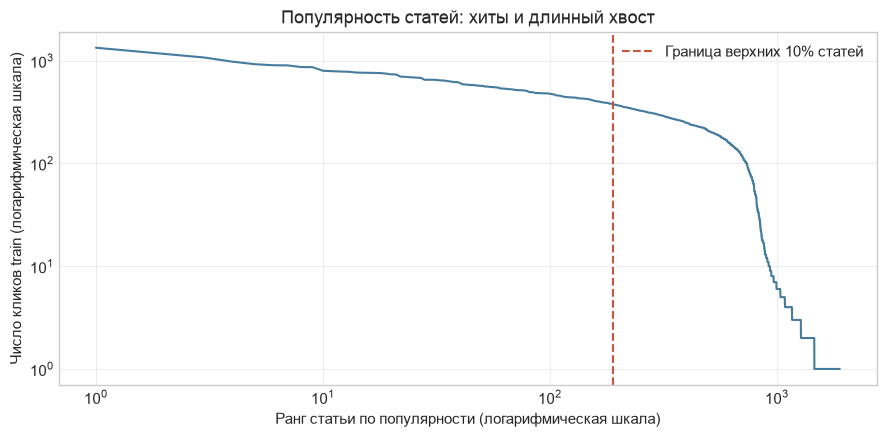

In [12]:
fig, ax = plt.subplots()
ax.plot(range(1, len(popularity) + 1), popularity.to_numpy(), color="#457b9d")
ax.set(xscale="log", yscale="log", title="Популярность статей: хиты и длинный хвост", xlabel="Ранг статьи по популярности (логарифмическая шкала)", ylabel="Число кликов train (логарифмическая шкала)")
ax.axvline(top_count, color="#c8553d", linestyle="--", label="Граница верхних 10% статей")
ax.legend()
fig.tight_layout()
plt.show()

**Интерпретация.** Самая популярная статья получила 1337 кликов, медианная - 8. Верхние 10% статей собирают 42,75% кликов: рекомендации хитов могут ограничивать новизну и покрытие

**Категории.** Сравниваем доли статей каталога и кликов train. Статья учитывается в каталоге один раз, в кликах - при каждом выборе, периоды и число показов различаются


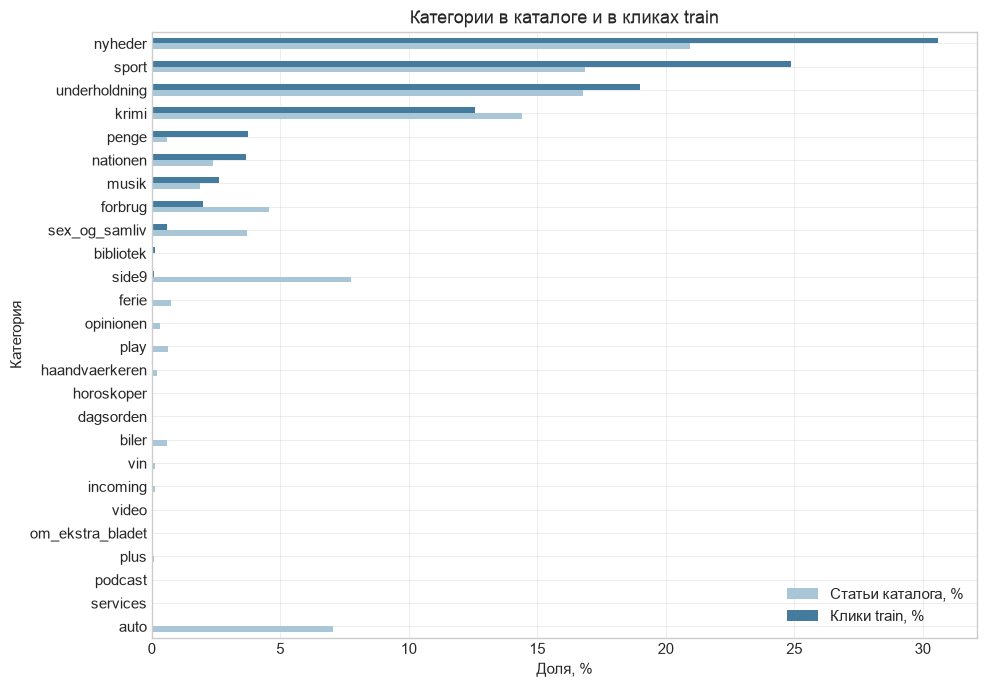

In [13]:
click_categories = train_clicks.merge(articles[["article_id", "category_str"]], on="article_id", how="left")["category_str"]
category_shares = pd.DataFrame({
    "Статьи каталога, %": 100 * articles["category_str"].value_counts(normalize=True),
    "Клики train, %": 100 * click_categories.value_counts(normalize=True),
}).fillna(0).sort_values("Клики train, %")

ax = category_shares.plot.barh(figsize=(10, 7), color=["#a8c6d6", "#457b9d"])
ax.set(title="Категории в каталоге и в кликах train", xlabel="Доля, %", ylabel="Категория")
ax.legend(loc="lower right")
ax.figure.tight_layout()
plt.show()

**Интерпретация.** `nyheder`, `sport` и `underholdning` дают 74,44% кликов, у некоторых категорий, например `auto`, кликов нет. Расхождение долей не доказывает предпочтение или отсутствие интереса без учета времени и показов

**Активность по дням.** Крайние дни train неполные, выделяем их на графике


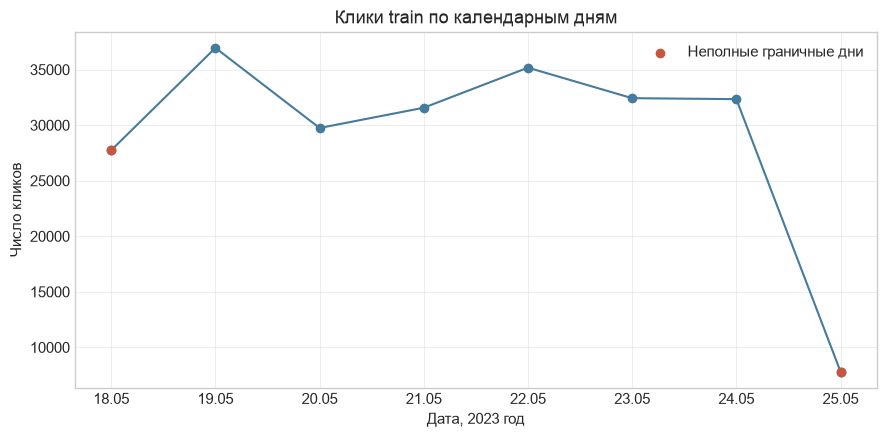

In [14]:
daily_clicks = train_clicks.groupby(train_clicks["impression_time"].dt.normalize()).size()
fig, ax = plt.subplots()
ax.plot(daily_clicks.index, daily_clicks.values, marker="o", color="#457b9d")
ax.scatter(daily_clicks.index[[0, -1]], daily_clicks.iloc[[0, -1]], color="#c8553d", zorder=3, label="Неполные граничные дни")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.set(title="Клики train по календарным дням", xlabel="Дата, 2023 год", ylabel="Число кликов")
ax.legend()
fig.tight_layout()
plt.show()

**Интерпретация.** В полные дни было 29 745-36 957 кликов. Низкое значение последнего дня связано с неполными сутками, одной недели недостаточно для вывода о сезонности

### Состав выборки

Считаем долю показов хотя бы с одним кликом


In [15]:
click_presence_rows = []
for name, behavior in [("train", train_behaviors), ("validation", validation_behaviors)]:
    clicked_lengths = behavior["article_ids_clicked"].map(len)
    click_presence_rows.append([name, len(behavior), (clicked_lengths > 0).sum(), 100 * (clicked_lengths > 0).mean()])

click_presence = pd.DataFrame(click_presence_rows, columns=["Часть", "Всего показов", "Показов с кликом", "Показов с кликом, %"])
display(click_presence)

,Часть,Всего показов,Показов с кликом,"Показов с кликом, %"
0,train,232887,232887,100.0
1,validation,244647,244647,100.0


### Выводы EDA

Все сохраненные показы содержат клик: выборка не описывает полный поток сайта. Разреженность обосновывает сравнение коллаборативных методов с MostPop, холодный старт - необходимость запасных правил, а категории позволяют дополнить точность оценкой разнообразия

## 3. Методы формирования рекомендации

### Обучение и тест

Сохраняем временное разделение датасета:

| Выборка | Данные |
|---|---|
| Обучающая | `train_history` и клики train до 25 мая 2023 года, 07:00 |
| Тестовая | `validation_behaviors`: следующая неделя, до 1 июня 2023 года, 07:00 |

### Выбор методов

| Метод | Семейство | Зачем включен |
|---|---|---|
| MostPop | Неперсонализированный | Базовый уровень по популярности |
| ItemKNN | Соседская коллаборативная фильтрация | Сходство кандидата с прочитанными статьями |
| iALS | Матричная факторизация | Скрытые интересы пользователей и свойства статей |

MostPop и ItemKNN реализованы на NumPy/SciPy, iALS - через `implicit==0.7.3`

### Матрица взаимодействий

Объединяем предысторию с кликами train и оставляем одну запись на пару пользователь-статья:

$$R_{u,i}=\begin{cases}1,&\text{если взаимодействие наблюдалось},\\0,&\text{иначе}\end{cases}$$

Матрицу храним в CSR, ID упорядочиваем. Повторные чтения не увеличивают вес пары. С добавлением предыстории плотность отличается от рассчитанной в EDA


In [16]:
history_clicks = (
    train_history[["user_id", "article_id_fixed"]]
    .explode("article_id_fixed")
    .rename(columns={"article_id_fixed": "article_id"})
)
training_pairs = (
    pd.concat([history_clicks, train_clicks[["user_id", "article_id"]]], ignore_index=True)
    .drop_duplicates(["user_id", "article_id"])
    .astype({"user_id": "int64", "article_id": "int64"})
    .reset_index(drop=True)
)

user_ids = np.sort(training_pairs["user_id"].unique())
article_ids = np.sort(training_pairs["article_id"].unique())
user_to_idx = {user_id: index for index, user_id in enumerate(user_ids)}
article_to_idx = {article_id: index for index, article_id in enumerate(article_ids)}

R = csr_matrix(
    (np.ones(len(training_pairs), dtype=np.float32), (
        training_pairs["user_id"].map(user_to_idx).to_numpy(),
        training_pairs["article_id"].map(article_to_idx).to_numpy(),
    )),
    shape=(len(user_ids), len(article_ids)),
    dtype=np.float32,
)

matrix_summary = pd.DataFrame({
    "Пользователей": [R.shape[0]],
    "Статей": [R.shape[1]],
    "Уникальных пар": [R.nnz],
    "Плотность, %": [100 * R.nnz / (R.shape[0] * R.shape[1])],
})
display(matrix_summary.round(2))

,Пользователей,Статей,Уникальных пар,"Плотность, %"
0,15143,9645,2281800,1.56


### MostPop

Оценка статьи - число уникальных читателей:

$$score(i)=|\mathcal U_i|=\sum_u R_{u,i}$$

В отличие от графика популярности в EDA, здесь учитываем предысторию и считаем пользователей, а не все клики


In [17]:
mostpop_scores = np.asarray(R.sum(axis=0)).ravel()

### ItemKNN: сходство Жаккара

$$sim(i,j)=\frac{|\mathcal U_i\cap\mathcal U_j|}{|\mathcal U_i|+|\mathcal U_j|-|\mathcal U_i\cap\mathcal U_j|}$$

Для кандидата $i$ оставляем до 50 положительных соседей, исключая саму статью, и суммируем сходства с прочитанными пользователем статьями:

$$score(u,i)=\sum_{j\in N_{50}(i)\cap\mathcal I_u}sim(i,j)$$

В `S` строка - кандидат, столбец - сосед. Пересечения читателей считаем матричным умножением блоками по 256 статей. При равном сходстве выбираем меньший ID. Сумма подходит бинарному фидбеку: взвешенное среднее единиц не различало бы кандидатов с попаданиями


In [18]:
def fit_item_knn(interactions, top_k=50, block_size=256):
    item_counts = np.asarray(interactions.sum(axis=0)).ravel()
    item_users = interactions.T.tocsr()
    n_items = interactions.shape[1]
    rows, columns, weights = [], [], []

    for start in range(0, n_items, block_size):
        stop = min(start + block_size, n_items)
        intersections = (item_users[start:stop] @ interactions).toarray()
        unions = item_counts[start:stop, None] + item_counts[None, :] - intersections
        similarities = intersections / unions
        similarities[np.arange(stop - start), np.arange(start, stop)] = 0

        for offset, similarities_row in enumerate(similarities):
            neighbors = np.argsort(-similarities_row, kind="stable")[:top_k]
            neighbors = neighbors[similarities_row[neighbors] > 0]
            rows.extend([start + offset] * len(neighbors))
            columns.extend(neighbors)
            weights.extend(similarities_row[neighbors])

    return csr_matrix(
        (weights, (rows, columns)), shape=(n_items, n_items), dtype=np.float32
    )

In [19]:
S = fit_item_knn(R, top_k=50, block_size=256)


### iALS

Предпочтение и уверенность:

$$p_{u,i}=R_{u,i},\qquad c_{u,i}=1+20R_{u,i}$$

Модель минимизирует взвешенную ошибку с регуляризацией, чередуя обновление факторов пользователей и статей:

$$\sum_{u,i}c_{u,i}(p_{u,i}-x_u^Ty_i)^2+\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right)$$

Оценка кандидата - $score(u,i)=x_u^Ty_i$. Настройки: **32 фактора, 15 итераций, регуляризация 0,1, `random_state=42`, CPU**

В `implicit` передаем копию `R` с весами 21 и `alpha=1`: для наблюдавшейся пары уверенность равна 21, для ненаблюдавшейся - 1. Исходную `R` не меняем


In [20]:
confidence = R.copy()
confidence.data[:] = 21.0

with threadpool_limits(limits=1, user_api="blas"):
    als_model = AlternatingLeastSquares(
        factors=32,
        iterations=15,
        regularization=0.1,
        alpha=1.0,
        random_state=42,
    )
    als_model.fit(confidence, show_progress=False)


### Общие правила ранжирования

`rank_candidates` принимает пользователя, кандидатов, метод и длину выдачи, возвращает ID и оценки

- Уже прочитанные статьи сохраняем: в данных встречается повторное чтение
- Для неизвестного пользователя используем MostPop
- Неизвестным статьям присваиваем `NaN` и ставим их после известных
- При равных оценках выбираем большую популярность, затем меньший ID
- Работаем с кандидатами исходных показов: в них не менее пяти уникальных статей

Оценки разных методов не сопоставимы по масштабу и не являются вероятностями клика


In [21]:
def rank_candidates(user_id, candidate_ids, method, top_n=5):
    candidates = np.asarray(candidate_ids, dtype=np.int64)
    result = pd.DataFrame({"article_id": candidates, "score": np.full(len(candidates), np.nan)})
    item_indices = np.array([article_to_idx.get(article_id, -1) for article_id in candidates])
    known = item_indices >= 0
    known_indices = item_indices[known]
    user_index = user_to_idx.get(user_id)
    popularity_scores = np.zeros(len(candidates), dtype=np.float32)
    popularity_scores[known] = mostpop_scores[known_indices]

    if method == "MostPop" or user_index is None:
        scores = mostpop_scores[known_indices]
    elif method == "ItemKNN":
        scores = (S[known_indices] @ R[user_index].T).toarray().ravel()
    else:
        scores = als_model.item_factors[known_indices] @ als_model.user_factors[user_index]

    result.loc[known, "score"] = scores
    result["_popularity"] = popularity_scores
    return (
        result.sort_values(
            ["score", "_popularity", "article_id"],
            ascending=[False, False, True],
            na_position="last",
        )
        .head(top_n)[["article_id", "score"]]
        .reset_index(drop=True)
    )


### Пример Top-5

Для первого по времени тестового показа известного пользователя выводим ID, заголовки, категории и оценки. Кандидаты одинаковы для всех методов, пример иллюстрирует выдачу, а не определяет лучший метод


In [22]:
demo_impression = (
    validation_behaviors[validation_behaviors["user_id"].isin(user_ids)]
    .sort_values(["impression_time", "impression_id"])
    .iloc[0]
)
demo_user = int(demo_impression["user_id"])
demo_candidates = demo_impression["article_ids_inview"]
demo_known = sum(article_id in article_to_idx for article_id in set(demo_candidates))

print(f"Показ: {demo_impression['impression_id']}, пользователь: {demo_user}")
print(f"Кандидатов: {len(set(demo_candidates))}, из них известных: {demo_known}")

for method in ["MostPop", "ItemKNN", "iALS"]:
    ranked = rank_candidates(demo_user, demo_candidates, method)
    ranked.insert(0, "Позиция", np.arange(1, len(ranked) + 1))
    ranked = ranked.merge(articles[["article_id", "title", "category_str"]], on="article_id", how="left", sort=False)
    print(method)
    display(ranked[["Позиция", "article_id", "title", "category_str", "score"]])

Показ: 349213169, пользователь: 1361500
Кандидатов: 6, из них известных: 6
MostPop


,Позиция,article_id,title,category_str,score
0,1,9779263,Vild hyre: Vælter sig i millioner,musik,225.0
1,2,9779577,Returamok: 42.000 Boozt-kunder ramt,nationen,218.0
2,3,9779713,Hylder Clara efter ny opvisning: - Vi kan till...,sport,97.0
3,4,9780195,"Elafgift rammer 2,8 millioner danskere",nyheder,35.0
4,5,9779564,Kvinde indrømmer stalking af stjerner: Brugte ...,sport,17.0


ItemKNN


,Позиция,article_id,title,category_str,score
0,1,9779577,Returamok: 42.000 Boozt-kunder ramt,nationen,0.317845
1,2,9779263,Vild hyre: Vælter sig i millioner,musik,0.286747
2,3,9779713,Hylder Clara efter ny opvisning: - Vi kan till...,sport,0.152577
3,4,9780195,"Elafgift rammer 2,8 millioner danskere",nyheder,0.000000
4,5,9779564,Kvinde indrømmer stalking af stjerner: Brugte ...,sport,0.000000


iALS


,Позиция,article_id,title,category_str,score
0,1,9779263,Vild hyre: Vælter sig i millioner,musik,0.387694
1,2,9779577,Returamok: 42.000 Boozt-kunder ramt,nationen,0.350815
2,3,9779713,Hylder Clara efter ny opvisning: - Vi kan till...,sport,0.245912
3,4,9779564,Kvinde indrømmer stalking af stjerner: Brugte ...,sport,0.107941
4,5,9780195,"Elafgift rammer 2,8 millioner danskere",nyheder,0.094147


## 4. Метрики качества

Используем **Recall@5** для попаданий, **NDCG@5** и **MRR@5** для порядка, **Category Diversity@5** для разнообразия. Основная метрика - NDCG@5. Все значения от 0 до 1, разнообразие рассматриваем вместе с релевантностью

Обозначения: $G$ - множество кликнутых статей показа, $L=(i_1,\ldots,i_5)$ - Top-5, $rel_r=\mathbb{1}[i_r\in G]$

**Recall@5** - доля кликнутых статей, попавших в пятерку:

$$Recall@5=\frac{|L\cap G|}{|G|}$$

**NDCG@5** учитывает позиции попаданий и нормирует результат на идеальный порядок:

$$DCG@5=\sum_{r=1}^{5}\frac{rel_r}{\log_2(r+1)},\qquad IDCG@5=\sum_{r=1}^{\min(5,|G|)}\frac{1}{\log_2(r+1)},\qquad NDCG@5=\frac{DCG@5}{IDCG@5}$$

**MRR@5** - среднее обратной позиции первого попадания: для показа $RR@5=1/r_*$, при отсутствии попаданий - 0. Последующие попадания эта метрика не учитывает

**Category Diversity@5** - доля пар статей с разными `category_str` среди 10 пар пятерки:

$$Category\ Diversity@5=\frac{1}{10}\sum_{1\leq a<b\leq5}\mathbb{1}[category(i_a)\ne category(i_b)]$$

### Почему Top-5?

Во всех тестовых показах не менее пяти уникальных кандидатов и есть клик, в 99,69% показов кликнута одна уникальная статья. В 16,41% показов кандидатов ровно пять: Recall@5 там всегда равна 1, а различия порядка отражают NDCG и MRR


In [23]:
category_by_id = articles.set_index("article_id")["category_str"].to_dict()
metric_names = ["Recall@5", "NDCG@5", "MRR@5", "Category Diversity@5"]
discounts = 1 / np.log2(np.arange(2, 7))


def recommendation_metrics(recommended_ids, clicked_ids, category_by_id):
    clicked = set(clicked_ids)
    relevance = np.array([article_id in clicked for article_id in recommended_ids])
    recall = relevance.sum() / len(clicked)
    ideal_dcg = discounts[:min(5, len(clicked))].sum()
    ndcg = (relevance * discounts).sum() / ideal_dcg
    hit_positions = np.flatnonzero(relevance)
    reciprocal_rank = 1 / (hit_positions[0] + 1) if len(hit_positions) else 0.0

    categories = [category_by_id[article_id] for article_id in recommended_ids]
    different_pairs = sum(
        categories[a] != categories[b] for a in range(5) for b in range(a + 1, 5)
    )
    return np.array([recall, ndcg, reciprocal_rank, different_pairs / 10])

## 5. Оценка и сравнение

### Расчет на тестовых показах

Сравниваем готовый Top-5 с `article_ids_clicked`, сохраняя порядок `rank_candidates`. Метрики усредняем по показам с одинаковым весом

Дополнительно выделяем показы известных пользователей, где все кликнутые статьи известны обучению. Кандидатов не фильтруем. Это диагностический срез, основной результат - оценка на всем тесте


In [ ]:
methods = ["MostPop", "ItemKNN", "iALS"]
metric_sums = np.zeros((2, len(methods), len(metric_names)))
evaluation_counts = np.zeros(2, dtype=int)
evaluation_columns = ["user_id", "article_ids_inview", "article_ids_clicked"]

for user_id, candidate_ids, clicked_ids in validation_behaviors[evaluation_columns].itertuples(index=False, name=None):
    known_case = user_id in user_to_idx and all(
        article_id in article_to_idx for article_id in set(clicked_ids)
    )
    evaluation_counts[0] += 1
    evaluation_counts[1] += known_case

    for method_index, method in enumerate(methods):
        recommended_ids = rank_candidates(user_id, candidate_ids, method, top_n=5)["article_id"].to_numpy()
        values = recommendation_metrics(recommended_ids, clicked_ids, category_by_id)
        metric_sums[0, method_index] += values
        if known_case:
            metric_sums[1, method_index] += values


In [ ]:
result_rows = []
for group_index, group in enumerate(["Вся тестовая выборка", "Известные пользователи и кликнутые статьи"]):
    for method_index, method in enumerate(methods):
        averages = metric_sums[group_index, method_index] / evaluation_counts[group_index]
        result_rows.append([group, method, evaluation_counts[group_index], *averages])

results = pd.DataFrame(result_rows, columns=["Выборка", "Метод", "Показов", *metric_names])
display(results.style.format({name: "{:.4f}" for name in metric_names}))


### Сравнение результатов

На всем тесте лидирует **iALS: NDCG@5 = 0,2792**, у MostPop - 0,2781, ItemKNN между ними. Разница с MostPop около 0,0011, Recall почти одинаков. Рост NDCG и MRR указывает на небольшое улучшение порядка попаданий, сопровождаемое снижением категориального разнообразия

Диагностический срез содержит **10 641 показ (4,35%)**. NDCG@5: **0,6011 у iALS против 0,5777 у MostPop**, iALS также лидирует по Recall и MRR

В остальных 95,65% показов неизвестен пользователь или хотя бы одна кликнутая статья. Поэтому общий результат сильно зависит от правил холодного старта. Более высокие метрики среза нельзя объяснять только персонализацией: он отобран по истинным кликам, а размещение известных статей выше новых благоприятствует известным кликнутым статьям

### Ограничения

- Оцениваем ранжирование сохраненных показов с кликом, метрики не измеряют реальный CTR сайта
- Общие правила холодного старта влияют на сравнение моделей
- Различия категорий приближенно отражают разнообразие тем. При пяти кандидатах разнообразие одинаково у всех методов
- Усреднение по показам сильнее учитывает активных пользователей

## 6. Улучшения и выводы

Предлагаем следующие эксперименты, их эффективность еще не проверена:

1. **Признаки новых статей:** профиль интересов по категориям и темам истории, затем - сходство текстов заголовков. Это даст оценки статьям без кликов
2. **Недавняя популярность:** запасная выдача для новых пользователей по короткому периоду, для статей без кликов - признаки или эвристика свежести
3. **Учет времени:** больший вес свежих взаимодействий и обновление моделей только по событиям до оцениваемого показа
4. **Подбор параметров:** число соседей ItemKNN, факторы, регуляризация и уверенность iALS. Использовать внутреннее временное разделение train, сохраняя тест для итоговой оценки
5. **Баланс точности и разнообразия:** выбирать менее однотипный состав Top-5 с контролем NDCG и Category Diversity. Одна перестановка позиций разнообразие не меняет

### Итог

Три семейства методов сравнены по четырем метрикам на следующей временной неделе. iALS показал наибольшую NDCG@5, но преимущество на полном тесте невелико
